# 03 — Fundamentos de PyTorch: da regressão logística "à mão" ao `nn.Module`

Este notebook é a parte **didática** do projeto de Deep Learning. Antes de construir uma rede neural (notebook 04), vamos entender o que acontece por dentro, implementando primeiro tudo manualmente com tensores e só depois substituindo cada peça pela abstração do PyTorch.

O fio condutor é uma ideia simples e importante:

> **A regressão logística é uma rede neural com um único neurônio.** Ela calcula uma soma ponderada das entradas, $z = \mathbf{x}\cdot\mathbf{w} + b$, e aplica a função sigmoide, $\hat{p} = \sigma(z)$. Uma rede neural "de verdade" empilha várias camadas desses neurônios.

Roteiro:

1. Tensores e dimensões.
2. Dos dados (pandas) para tensores.
3. Regressão logística manual: *forward*, função de perda e **gradiente derivado à mão**.
4. *Autograd*: o PyTorch calcula o mesmo gradiente automaticamente (backpropagation).
5. Conferência com o scikit-learn.
6. A versão "oficial": `nn.Module`, `nn.Linear`, `BCEWithLogitsLoss`, `torch.optim`.
7. `Dataset` e `DataLoader`: mini-lotes (*mini-batches*).
8. Otimizadores: SGD, SGD com momento e Adam.

Os dados são os mesmos de todo o projeto: `data/splits/treino.csv` (614 pacientes) e `teste.csv` (154), com o mesmo pré-processamento (zeros → NaN, mediana, padronização).

In [1]:
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from torch.utils.data import DataLoader, Dataset, TensorDataset

from diabetes.config import FEATURES, RANDOM_SEED, TABLES_DIR
from diabetes.data import load_splits
from diabetes.evaluation import compute_metrics
from diabetes.plotting import apply_style, save_fig
from diabetes.preprocessing import build_preprocessor

apply_style()
pd.set_option("display.precision", 4)
torch.manual_seed(RANDOM_SEED)
print("PyTorch", torch.__version__)

PyTorch 2.15.0+cpu


## 1. Tensores e dimensões

Um **tensor** é um array multidimensional, como um `ndarray` do NumPy, com dois superpoderes: pode rodar em GPU e **registra as operações feitas sobre ele** para calcular derivadas automaticamente (§4).

A propriedade mais importante no dia a dia é o **shape** (formato). Em dados tabulares a convenção é:

- `X` tem shape `(N, d)`: **N amostras** (linhas, pacientes) por **d variáveis** (colunas). Aqui `(614, 8)`.
- Os pesos `w` têm shape `(d, 1)`, e `X @ w` tem shape `(N, 1)`: um valor por paciente.

In [2]:
a = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])            # 2 amostras x 3 variáveis
w = torch.tensor([[0.5], [-1.0], [2.0]])        # 3 pesos -> shape (3, 1)

print("a.shape   =", a.shape, "| dtype:", a.dtype)
print("w.shape   =", w.shape)
print("a @ w     =", (a @ w).squeeze().tolist(), "-> shape", (a @ w).shape, "(produto matricial)")
print("a * 10    =", (a * 10).tolist(), "(operação elemento a elemento)")
print("a.mean(0) =", a.mean(dim=0).tolist(), "(média por coluna: reduz a dimensão 0, das amostras)")
print("a.mean(1) =", a.mean(dim=1).tolist(), "(média por linha: reduz a dimensão 1, das variáveis)")

a.shape   = torch.Size([2, 3]) | dtype: torch.float32
w.shape   = torch.Size([3, 1])
a @ w     = [4.5, 9.0] -> shape torch.Size([2, 1]) (produto matricial)
a * 10    = [[10.0, 20.0, 30.0], [40.0, 50.0, 60.0]] (operação elemento a elemento)
a.mean(0) = [2.5, 3.5, 4.5] (média por coluna: reduz a dimensão 0, das amostras)
a.mean(1) = [2.0, 5.0] (média por linha: reduz a dimensão 1, das variáveis)


**Broadcasting.** Quando dois tensores têm shapes diferentes, o PyTorch "estica" as dimensões de tamanho 1 para que fiquem compatíveis. É o que permite somar o viés `b` (um escalar) a todas as linhas de `X @ w`. Mas o broadcasting também esconde um **erro clássico**: subtrair um vetor `(N,)` de uma coluna `(N, 1)` não dá erro, e sim uma matriz `(N, N)`.

In [3]:
y_coluna = torch.zeros(5, 1)    # shape (5, 1)
y_vetor = torch.zeros(5)        # shape (5,)
print("(5,1) - (5,)  ->", (y_coluna - y_vetor).shape, " <- 25 valores em vez de 5: bug silencioso!")
print("(5,1) - (5,1) ->", (y_coluna - y_vetor.unsqueeze(1)).shape, " <- correto")

(5,1) - (5,)  -> torch.Size([5, 5])  <- 25 valores em vez de 5: bug silencioso!
(5,1) - (5,1) -> torch.Size([5, 1])  <- correto


Por isso, neste projeto, **o alvo `y` sempre terá shape `(N, 1)`**, igual à saída do modelo.

## 2. Dos dados para tensores

O pré-processador é o mesmo do scikit-learn (notebook 02), **ajustado só no treino**. Depois convertemos os arrays NumPy em tensores `float32`, o tipo padrão das redes neurais: tem precisão suficiente e ocupa metade da memória do `float64`.

In [4]:
X_train_df, y_train_s, X_test_df, y_test_s = load_splits()

prep = build_preprocessor().fit(X_train_df)          # mediana e z-score aprendidos no treino
X_train = torch.tensor(prep.transform(X_train_df), dtype=torch.float32)
X_test = torch.tensor(prep.transform(X_test_df), dtype=torch.float32)
y_train = torch.tensor(y_train_s.values, dtype=torch.float32).unsqueeze(1)   # (N,) -> (N, 1)
y_test = torch.tensor(y_test_s.values, dtype=torch.float32).unsqueeze(1)

print("X_train:", tuple(X_train.shape), "| y_train:", tuple(y_train.shape))
print("X_test: ", tuple(X_test.shape), "| y_test: ", tuple(y_test.shape))
print("Média por coluna (≈0 após padronização):", np.round(X_train.mean(0).numpy(), 3).tolist())
print("Desvio por coluna (≈1):                 ", np.round(X_train.std(0, correction=0).numpy(), 3).tolist())
# correction=0 divide por N, como o StandardScaler; o padrão do PyTorch divide por N-1 e daria 1,001.

X_train: (614, 8) | y_train: (614, 1)
X_test:  (154, 8) | y_test:  (154, 1)
Média por coluna (≈0 após padronização): [0.0, 0.0, -0.0, 0.0, -0.0, 0.0, -0.0, 0.0]
Desvio por coluna (≈1):                  [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


## 3. Regressão logística implementada à mão

### 3.1 Propagação direta (*forward*)

Para cada paciente $i$ com variáveis $\mathbf{x}_i \in \mathbb{R}^8$:

$$z_i = \mathbf{x}_i \cdot \mathbf{w} + b \qquad \text{(logit: um número real qualquer)}$$

$$\hat{p}_i = \sigma(z_i) = \frac{1}{1 + e^{-z_i}} \qquad \text{(probabilidade de diabetes, entre 0 e 1)}$$

Em forma matricial, para todas as pacientes de uma vez: $\mathbf{z} = X\mathbf{w} + b$, com shape `(N, 1)`.

### 3.2 Função de perda: entropia cruzada binária (BCE)

Precisamos de um número que diga "quão errado" o modelo está. Para classificação binária usamos a **entropia cruzada binária**:

$$L = -\frac{1}{N}\sum_{i=1}^{N}\Big[\,y_i \log \hat{p}_i + (1 - y_i)\log(1 - \hat{p}_i)\,\Big]$$

Intuição: se $y_i = 1$, sobra só $-\log \hat{p}_i$, que é 0 quando $\hat{p}_i = 1$ e cresce sem limite quando $\hat{p}_i \to 0$. **Errar com confiança custa muito caro.**

De onde ela vem? Se cada $y_i$ segue uma distribuição de Bernoulli com probabilidade $\hat{p}_i$, a verossimilhança dos dados é $\prod_i \hat{p}_i^{\,y_i}(1-\hat{p}_i)^{1-y_i}$. Tomando $-\log$ e a média, obtemos exatamente $L$. **Minimizar a BCE é maximizar a verossimilhança.**

### 3.3 O gradiente, derivado à mão

Para minimizar $L$ por **gradiente descendente**, precisamos de $\partial L / \partial \mathbf{w}$ e $\partial L / \partial b$. Pela regra da cadeia, $\frac{\partial L}{\partial w_j} = \sum_i \frac{\partial L}{\partial \hat{p}_i}\cdot\frac{\partial \hat{p}_i}{\partial z_i}\cdot\frac{\partial z_i}{\partial w_j}$, com:

- $\dfrac{\partial L}{\partial \hat{p}_i} = -\dfrac{1}{N}\left(\dfrac{y_i}{\hat{p}_i} - \dfrac{1-y_i}{1-\hat{p}_i}\right)$
- $\dfrac{\partial \hat{p}_i}{\partial z_i} = \sigma(z_i)\,(1-\sigma(z_i)) = \hat{p}_i(1-\hat{p}_i)$ (a derivada da sigmoide)
- $\dfrac{\partial z_i}{\partial w_j} = x_{ij}$

Multiplicando os dois primeiros termos, quase tudo se cancela:

$$\frac{\partial L}{\partial z_i} = \frac{1}{N}(\hat{p}_i - y_i)$$

E então, em forma matricial:

$$\boxed{\;\nabla_{\mathbf{w}} L = \frac{1}{N} X^\top(\hat{\mathbf{p}} - \mathbf{y}) \qquad \frac{\partial L}{\partial b} = \frac{1}{N}\sum_i (\hat{p}_i - y_i)\;}$$

O resultado é elegante: o gradiente é o **erro de previsão** $(\hat{p} - y)$ ponderado pelas entradas.

### 3.4 Gradiente descendente

A cada passo, andamos um pouco na direção oposta ao gradiente (a direção em que a perda diminui mais rápido):

$$\mathbf{w} \leftarrow \mathbf{w} - \eta\,\nabla_{\mathbf{w}} L \qquad b \leftarrow b - \eta\,\frac{\partial L}{\partial b}$$

onde $\eta$ é a **taxa de aprendizado** (*learning rate*). Usamos todas as 614 pacientes em cada passo (*batch gradient descent*).

Perda inicial: 0.6931 (= ln 2 ≈ 0.6931: com w = 0, p = 0,5 para todas)
Perda final:   0.4531


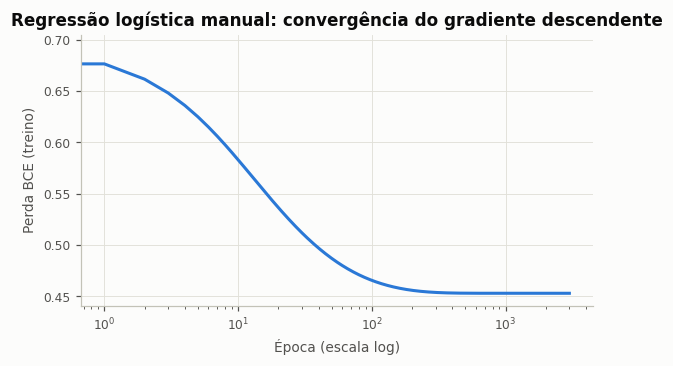

In [5]:
def sigmoid(z):
    return 1 / (1 + torch.exp(-z))


def bce(p, y):
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean()


N, d = X_train.shape
w = torch.zeros(d, 1)          # começamos com todos os pesos zerados
b = torch.zeros(1)
lr = 0.1
manual_losses = []

for epoch in range(3000):
    # forward
    p = sigmoid(X_train @ w + b)
    manual_losses.append(bce(p, y_train).item())
    # gradiente analítico (§3.3)
    error = p - y_train                    # (N, 1)
    grad_w = X_train.T @ error / N         # (d, N) @ (N, 1) -> (d, 1)
    grad_b = error.mean()
    # passo de gradiente descendente
    w -= lr * grad_w
    b -= lr * grad_b

w_manual, b_manual = w.clone(), b.clone()
print(f"Perda inicial: {manual_losses[0]:.4f} (= ln 2 ≈ 0.6931: com w = 0, p = 0,5 para todas)")
print(f"Perda final:   {manual_losses[-1]:.4f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(manual_losses, color="#2a78d6", linewidth=2)
ax.set_xscale("log")
ax.set_xlabel("Época (escala log)")
ax.set_ylabel("Perda BCE (treino)")
ax.set_title("Regressão logística manual: convergência do gradiente descendente")
save_fig(fig, "20_pytorch_rl_manual_perda")
plt.show()

**Observações**

- A perda começa em **0,6931 = ln 2**. Com todos os pesos zerados, o modelo prevê $\hat p = 0{,}5$ para todas as pacientes, e $-\ln 0{,}5 = \ln 2$. É uma boa verificação de sanidade.
- Depois de 3000 épocas a perda chega a **0,4531**. A §5 confirma que esse é o mínimo.
- **Por que dá para confiar que é *o* mínimo?** A BCE da regressão logística é uma função **convexa** dos pesos, com formato de "tigela": não tem mínimos locais falsos. Com uma taxa de aprendizado adequada, o gradiente descendente chega ao mesmo ponto qualquer que seja o ponto de partida. Isso deixa de valer nas redes com camadas ocultas (notebook 04), cuja função de perda não é convexa.

## 4. Autograd: o PyTorch calcula o gradiente sozinho

Derivar gradientes à mão funciona para um neurônio, mas é inviável para redes com milhares de parâmetros. O **autograd** resolve isso:

1. Marcamos os parâmetros com `requires_grad=True`.
2. Durante o *forward*, o PyTorch monta um **grafo computacional** com cada operação feita (multiplicação, soma, sigmoide, log...).
3. `loss.backward()` percorre esse grafo **de trás para frente**, aplicando a regra da cadeia em cada nó. Isso é a **retropropagação** (*backpropagation*).
4. O gradiente de cada parâmetro fica em `.grad`.

Vamos conferir: no mesmo ponto de partida, o gradiente do autograd deve ser idêntico ao da fórmula da §3.3.

In [6]:
torch.manual_seed(RANDOM_SEED)
w = torch.randn(d, 1, requires_grad=True)     # ponto aleatório (com zeros, o teste seria fácil demais)
b = torch.randn(1, requires_grad=True)

p = torch.sigmoid(X_train @ w + b)
loss = bce(p, y_train)
loss.backward()                               # backpropagation

with torch.no_grad():                         # cálculo manual não precisa entrar no grafo
    error = p - y_train
    grad_w_formula = X_train.T @ error / N
    grad_b_formula = error.mean()

print("grad_fn da perda:", loss.grad_fn)
print("Gradiente de w (autograd):", w.grad.squeeze().round(decimals=5).tolist())
print("Gradiente de w (fórmula): ", grad_w_formula.squeeze().round(decimals=5).tolist())
print("Iguais?", torch.allclose(w.grad, grad_w_formula, atol=1e-6),
      "| viés iguais?", torch.allclose(b.grad, grad_b_formula.reshape(1), atol=1e-6))

grad_fn da perda: <NegBackward0 object at 0x000002BB392A8AF0>
Gradiente de w (autograd): [-0.11832000315189362, -0.27008000016212463, -0.09015999734401703, -0.09854000061750412, -0.19904999434947968, -0.14608000218868256, 0.15222999453544617, -0.18227000534534454]
Gradiente de w (fórmula):  [-0.11832000315189362, -0.27008000016212463, -0.09015999734401703, -0.09854000061750412, -0.19904999434947968, -0.14608000218868256, 0.15222999453544617, -0.18227000534534454]
Iguais? True | viés iguais? True


**Armadilha importante: os gradientes se acumulam.** Cada chamada de `backward()` *soma* ao `.grad` que já existe, em vez de substituí-lo. (Isso é útil em casos avançados, como acumular gradientes de vários lotes.) Por isso todo laço de treino zera os gradientes a cada passo:

In [7]:
grad_antes = w.grad.clone()
bce(torch.sigmoid(X_train @ w + b), y_train).backward()     # segundo backward sem zerar
print("Após 2 backward() sem zerar, grad = 2x o correto?", torch.allclose(w.grad, 2 * grad_antes))
w.grad.zero_()
b.grad.zero_()
print("Após .zero_():", w.grad.abs().sum().item())

Após 2 backward() sem zerar, grad = 2x o correto? True
Após .zero_(): 0.0


## 5. Conferência com o scikit-learn

Se a implementação manual estiver correta, ela deve chegar aos **mesmos coeficientes** que a `LogisticRegression` do scikit-learn **sem regularização** (`C=np.inf`), pois ambas minimizam exatamente a mesma função de perda nos mesmos dados.

In [8]:
sk_lr = LogisticRegression(C=np.inf, max_iter=10_000).fit(X_train.numpy(), y_train_s.values)

coef = pd.DataFrame({
    "manual (gradiente descendente)": w_manual.squeeze().numpy(),
    "scikit-learn (lbfgs, sem regularização)": sk_lr.coef_.ravel(),
}, index=FEATURES)
coef.loc["(viés / intercepto)"] = [b_manual.item(), sk_lr.intercept_[0]]
coef["diferença absoluta"] = (coef.iloc[:, 0] - coef.iloc[:, 1]).abs()
display(coef)

with torch.no_grad():
    p_test_manual = torch.sigmoid(X_test @ w_manual + b_manual).squeeze().numpy()
p_test_sk = sk_lr.predict_proba(X_test.numpy())[:, 1]
comparison = pd.DataFrame({
    "manual": compute_metrics(y_test_s, (p_test_manual >= 0.5).astype(int), p_test_manual),
    "scikit-learn": compute_metrics(y_test_s, (p_test_sk >= 0.5).astype(int), p_test_sk),
}).T
comparison

C:\Users\lucas\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


,manual (gradiente descendente),"scikit-learn (lbfgs, sem regularização)",diferença absoluta
Gavidez,0.3857,0.3860,3.2929e-04
Glicose,1.2070,1.2069,8.0695e-05
PressaoArterial,-0.0507,-0.0504,3.2805e-04
Espesura_da_Pele,0.0214,0.0218,3.3820e-04
Insulina,-0.0761,-0.0761,7.8667e-05
IMC,0.7060,0.7056,4.0262e-04
Diabetes_Hereditaria,0.2366,0.2367,1.5207e-04
Idade,0.1466,0.1459,6.2480e-04
(viés / intercepto),-0.8772,-0.8770,1.5977e-04


,acurácia,precisão,recall,especificidade,f1,roc_auc,VN,FP,FN,VP
manual,0.7078,0.6,0.5,0.82,0.5455,0.8133,82.0,18.0,27.0,27.0
scikit-learn,0.7078,0.6,0.5,0.82,0.5455,0.8131,82.0,18.0,27.0,27.0


**Observações**

- Os coeficientes manuais e os do scikit-learn diferem em no máximo **≈ 0,0006**, uma diferença de tolerância numérica. As métricas no teste são idênticas. **A implementação manual está correta.** O gradiente descendente "artesanal" e o otimizador L-BFGS do scikit-learn chegam ao mesmo lugar por caminhos diferentes.
- **Interpretação dos coeficientes.** Como as variáveis estão padronizadas, cada coeficiente é o efeito de **+1 desvio-padrão** sobre o *log-odds* de diabetes. Exponenciando, obtemos a **razão de chances** (*odds ratio*):
  - `Glicose`: $e^{1{,}207} \approx 3{,}3$. Cada desvio-padrão a mais de glicose multiplica a chance de diabetes por cerca de 3,3, com as demais variáveis fixas.
  - `IMC`: $e^{0{,}706} \approx 2{,}0$.
  - `Gavidez`: $e^{0{,}386} \approx 1{,}5$.
- `Insulina`, `PressaoArterial` e `Espesura_da_Pele` ficam com coeficientes **perto de zero**, embora na EDA (§8) cada uma, sozinha, diferisse entre as classes. Não há contradição. *Dadas* a glicose e o IMC, elas acrescentam pouca informação nova: a insulina é correlacionada com a glicose (r = 0,58) e a dobra cutânea com o IMC (r = 0,65). O modelo multivariado mede a contribuição **condicional** de cada variável.
- No teste, este modelo sem regularização detecta só **27 das 54 diabéticas (recall 0,50)**. O notebook 02 avalia os modelos ajustados com mais cuidado.

## 6. A versão "oficial": `nn.Module`, `BCEWithLogitsLoss` e `torch.optim`

Agora substituímos cada peça manual pela abstração do PyTorch:

| Peça manual | Abstração do PyTorch | O que ela faz por nós |
|---|---|---|
| `w`, `b` e `X @ w + b` | `nn.Linear(8, 1)` | Cria e registra os parâmetros, com inicialização adequada. |
| a função `forward` | uma classe filha de `nn.Module` | Organiza parâmetros e camadas; permite `model(X)`, `model.parameters()`, `model.train()`/`model.eval()`, salvar e carregar. |
| `sigmoid` + `bce` | `nn.BCEWithLogitsLoss` | Calcula a BCE a partir do **logit** $z$, de forma numericamente estável. |
| `w -= lr * grad` | `torch.optim.SGD` | Aplica a regra de atualização a todos os parâmetros. |

### Por que `BCEWithLogitsLoss` e não sigmoide + BCE?

Em `float32`, $\sigma(40)$ arredonda para **exatamente 1,0**. Se a paciente for da classe 0, a perda envolve $\log(1 - 1) = \log 0 = -\infty$. A versão "com logits" reescreve a conta algebricamente (truque *log-sum-exp*):

$$-\big[y\log\sigma(z) + (1-y)\log(1-\sigma(z))\big] = \max(z, 0) - z\,y + \log\!\left(1 + e^{-|z|}\right)$$

Essa forma nunca calcula $\log 0$. Veja a diferença:

In [9]:
z = torch.tensor([40.0])        # logit muito confiante na classe 1...
y = torch.tensor([0.0])         # ...mas a paciente é da classe 0
p = torch.sigmoid(z)
print(f"sigmoid(40) em float32 = {p.item()}  ->  1 - p = {(1 - p).item()}")
print(f"BCE manual:              {bce(p, y).item()}")
print(f"nn.BCELoss (sobre p):    {nn.BCELoss()(p, y).item()}  <- o PyTorch limita log(0) a -100: valor errado, mas finito")
print(f"nn.BCEWithLogitsLoss(z): {nn.BCEWithLogitsLoss()(z, y).item()}  <- valor exato (= z, já que log(1+e^-40) ≈ 0)")

sigmoid(40) em float32 = 1.0  ->  1 - p = 0.0
BCE manual:              inf
nn.BCELoss (sobre p):    100.0  <- o PyTorch limita log(0) a -100: valor errado, mas finito
nn.BCEWithLogitsLoss(z): 40.0  <- valor exato (= z, já que log(1+e^-40) ≈ 0)


Por isso, **o modelo devolve logits** e a sigmoide só é aplicada na hora de prever probabilidades.

### O laço de treino padrão

Todo treino em PyTorch segue os mesmos cinco passos:

```
optimizer.zero_grad()      # 1. zera os gradientes acumulados (§4)
logits = model(X)          # 2. forward
loss = loss_fn(logits, y)  # 3. perda
loss.backward()            # 4. backpropagation
optimizer.step()           # 5. atualiza os parâmetros
```

In [10]:
class LogisticRegressionNN(nn.Module):
    # Regressão logística como uma rede neural de um único neurônio.

    def __init__(self, n_features: int):
        super().__init__()
        self.linear = nn.Linear(n_features, 1)     # z = x·w + b

    def forward(self, x):
        return self.linear(x)                      # devolve o LOGIT (sem sigmoide)


torch.manual_seed(RANDOM_SEED)
model = LogisticRegressionNN(n_features=d)
print(model)
for name, param in model.named_parameters():
    print(f"  {name:15s} shape={tuple(param.shape)}")

loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

module_losses = []
for epoch in range(3000):
    optimizer.zero_grad()
    logits = model(X_train)
    loss = loss_fn(logits, y_train)
    loss.backward()
    optimizer.step()
    module_losses.append(loss.item())

print(f"\nPerda final: nn.Module = {module_losses[-1]:.4f} | manual = {manual_losses[-1]:.4f}")
print("Pesos aprendidos ≈ pesos manuais?",
      torch.allclose(model.linear.weight.detach().T, w_manual, atol=1e-3))

LogisticRegressionNN(
  (linear): Linear(in_features=8, out_features=1, bias=True)
)
  linear.weight   shape=(1, 8)
  linear.bias     shape=(1,)



Perda final: nn.Module = 0.4531 | manual = 0.4531
Pesos aprendidos ≈ pesos manuais? True


**Observações**

- O `nn.Module` treinado com `torch.optim.SGD` atinge a **mesma perda (0,4531)** e os **mesmos pesos** da versão manual. Isso vale mesmo partindo de pesos *aleatórios* (o `nn.Linear` não inicializa com zeros), graças à convexidade vista na §3.
- O código ficou menor e, principalmente, **genérico**: o laço de cinco passos acima serve igualmente para uma rede com milhões de parâmetros. Basta trocar a classe do modelo.
- `nn.Linear` guarda o peso com shape `(1, 8)` (saídas × entradas), o transposto do nosso `w` manual `(8, 1)`. Por isso a comparação usa `.T`.

## 7. `Dataset` e `DataLoader`: treinando em mini-lotes

Até aqui cada passo usou **todas** as 614 pacientes. Em conjuntos grandes isso é lento ou nem cabe na memória. A alternativa é calcular o gradiente em pequenos **lotes** (*batches*):

| Variante | Pacientes por passo | Passos por época (614 pacientes) |
|---|---|---|
| Gradiente descendente em lote (*batch*) | 614 | 1 |
| Mini-lote (*mini-batch*) | 32 | 20 |
| Estocástico "puro" (SGD) | 1 | 614 |

Uma **época** é uma passada completa pelos dados. O gradiente de um mini-lote é uma **estimativa ruidosa** do gradiente verdadeiro: mais barata de calcular e, na prática, o ruído até ajuda a escapar de regiões ruins da função de perda.

O PyTorch separa duas responsabilidades:

- **`Dataset`**: sabe *quantas* amostras existem (`__len__`) e *como obter* a amostra `i` (`__getitem__`).
- **`DataLoader`**: agrupa amostras em lotes, embaralha a cada época (`shuffle=True`) e pode carregar dados em paralelo.

In [11]:
class DiabetesDataset(Dataset):
    # Dataset mínimo: guarda os tensores e devolve uma paciente por índice.

    def __init__(self, X: torch.Tensor, y: torch.Tensor):
        self.X, self.y = X, y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return self.X[i], self.y[i]


train_ds = DiabetesDataset(X_train, y_train)
print("len(train_ds) =", len(train_ds), "| train_ds[0] =", [t.shape for t in train_ds[0]])

loader = DataLoader(train_ds, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(RANDOM_SEED))
xb, yb = next(iter(loader))
print("Um lote:", tuple(xb.shape), tuple(yb.shape), "| lotes por época:", len(loader))
print("(TensorDataset(X, y) faz exatamente o mesmo que a classe acima, sem precisar escrevê-la.)")

len(train_ds) = 614 | train_ds[0] = [torch.Size([8]), torch.Size([1])]
Um lote: (32, 8) (32, 1) | lotes por época: 20
(TensorDataset(X, y) faz exatamente o mesmo que a classe acima, sem precisar escrevê-la.)


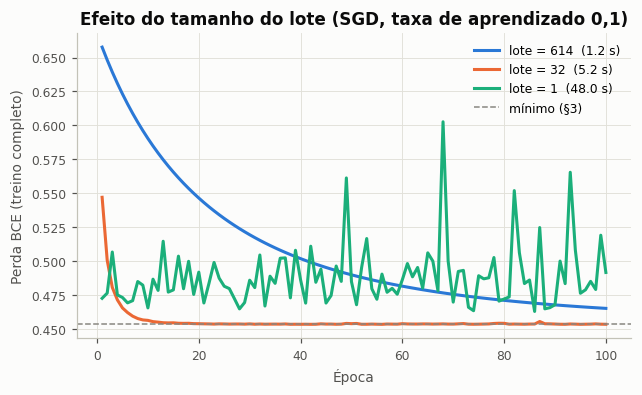

,perda após 5 épocas,perda após 100 épocas,tempo (s)
lote = 614,0.6231,0.4649,1.2349
lote = 32,0.4653,0.4532,5.2264
lote = 1,0.4730,0.4914,48.0272


In [12]:
def train_epochs(batch_size, optimizer_name, lr, n_epochs, seed=RANDOM_SEED):
    # Treina a regressão logística e devolve a perda no treino COMPLETO ao fim de cada época.
    torch.manual_seed(seed)
    model = LogisticRegressionNN(d)
    optimizers = {
        "SGD": lambda p: torch.optim.SGD(p, lr=lr),
        "SGD + momento": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9),
        "Adam": lambda p: torch.optim.Adam(p, lr=lr),
    }
    optimizer = optimizers[optimizer_name](model.parameters())
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    history = []
    start = time.perf_counter()
    for _ in range(n_epochs):
        for xb, yb in loader:
            optimizer.zero_grad()
            loss_fn(model(xb), yb).backward()
            optimizer.step()
        with torch.no_grad():
            history.append(loss_fn(model(X_train), y_train).item())
    return history, time.perf_counter() - start


batch_runs = {f"lote = {bs}": train_epochs(bs, "SGD", lr=0.1, n_epochs=100) for bs in [614, 32, 1]}

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for (label, (hist, secs)), color in zip(batch_runs.items(), ["#2a78d6", "#eb6834", "#1baf7a"]):
    ax.plot(range(1, len(hist) + 1), hist, color=color, linewidth=2, label=f"{label}  ({secs:.1f} s)")
ax.axhline(manual_losses[-1], color="#898781", linestyle="--", linewidth=1, label="mínimo (§3)")
ax.set_xlabel("Época")
ax.set_ylabel("Perda BCE (treino completo)")
ax.set_title("Efeito do tamanho do lote (SGD, taxa de aprendizado 0,1)")
ax.legend()
save_fig(fig, "21_pytorch_tamanho_lote")
plt.show()

pd.DataFrame({k: {"perda após 5 épocas": h[4], "perda após 100 épocas": h[-1], "tempo (s)": s}
              for k, (h, s) in batch_runs.items()}).T

**Observações**

- **Por época**, lotes menores progridem mais rápido. Após 5 épocas, o lote completo deu só 5 passos (perda 0,623), enquanto o mini-lote de 32 deu 100 passos (0,465). Com 100 épocas o lote completo ainda não convergiu (0,465), pois precisa de milhares de passos (§3).
- **Lote = 1 termina *pior*** (0,491) que o mini-lote (0,453). Com uma taxa de aprendizado fixa de 0,1, o gradiente de uma única paciente é tão ruidoso que os parâmetros ficam "pulando" em volta do mínimo sem se acomodar. Na prática, isso se resolve reduzindo a taxa de aprendizado ao longo do treino (*learning-rate schedule*).
- **Tempo:** lote 1 levou cerca de **uma ordem de grandeza** mais tempo que o mini-lote (o fator exato varia entre execuções e máquinas; veja a tabela), porque fez 614 passos por época, cada um com o custo fixo de uma chamada Python. Lotes maiores aproveitam operações matriciais vetorizadas (e, em GPU, paralelismo massivo).
- **Conclusão:** o mini-lote é o melhor compromisso entre ruído, velocidade de convergência e custo computacional. Por isso é o padrão; tamanhos entre 16 e 256 são comuns.

## 8. Otimizadores: SGD, momento e Adam

Todos os otimizadores usam o gradiente $g_t = \nabla L(\theta_t)$, mas de formas diferentes:

**SGD:** $\theta_{t+1} = \theta_t - \eta\, g_t$. Simples, mas lento em "vales" estreitos, onde fica oscilando de um lado para o outro.

**SGD com momento:** acumula uma "velocidade" que é uma média móvel dos gradientes passados:

$$v_{t+1} = \mu\, v_t + g_t \qquad \theta_{t+1} = \theta_t - \eta\, v_{t+1} \qquad (\mu \approx 0{,}9)$$

Como uma bola descendo uma ladeira, ganha velocidade nas direções consistentes e amortece as oscilações.

**Adam** (*adaptive moment estimation*): combina momento com uma **taxa de aprendizado adaptativa por parâmetro**:

$$m_t = \beta_1 m_{t-1} + (1-\beta_1)\,g_t \qquad \text{(média dos gradientes: o momento)}$$
$$v_t = \beta_2 v_{t-1} + (1-\beta_2)\,g_t^2 \qquad \text{(média dos gradientes ao quadrado)}$$
$$\theta_{t+1} = \theta_t - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}$$

($\hat m_t$ e $\hat v_t$ são versões corrigidas do viés inicial causado por começarem em zero.) A divisão por $\sqrt{\hat v_t}$ faz com que parâmetros com gradientes grandes deem passos menores, e vice-versa. Na prática, o Adam funciona bem "de fábrica" com pouco ajuste, por isso é o padrão em Deep Learning.

Comparação justa: mesmos dados, mesmo lote (32), mesma semente, **mesma taxa de aprendizado (0,01)**.

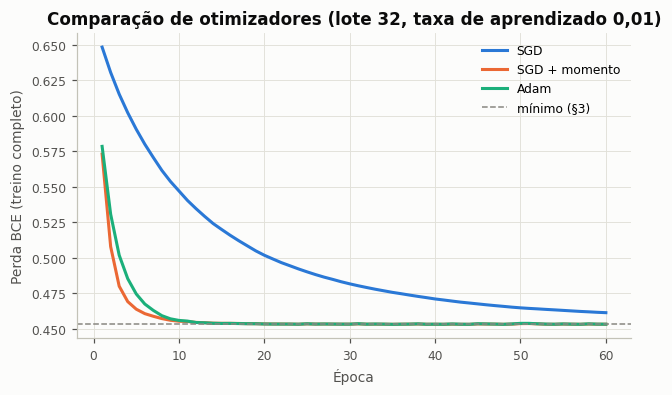

,perda após 5 épocas,perda após 20 épocas,perda após 60 épocas
SGD,0.5905,0.5018,0.4614
SGD + momento,0.4638,0.4534,0.4532
Adam,0.4745,0.4534,0.4532


In [13]:
opt_runs = {name: train_epochs(32, name, lr=0.01, n_epochs=60) for name in ["SGD", "SGD + momento", "Adam"]}

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for (name, (hist, _)), color in zip(opt_runs.items(), ["#2a78d6", "#eb6834", "#1baf7a"]):
    ax.plot(range(1, len(hist) + 1), hist, color=color, linewidth=2, label=name)
ax.axhline(manual_losses[-1], color="#898781", linestyle="--", linewidth=1, label="mínimo (§3)")
ax.set_xlabel("Época")
ax.set_ylabel("Perda BCE (treino completo)")
ax.set_title("Comparação de otimizadores (lote 32, taxa de aprendizado 0,01)")
ax.legend()
save_fig(fig, "22_pytorch_otimizadores")
plt.show()

pd.DataFrame({k: {"perda após 5 épocas": h[4], "perda após 20 épocas": h[19], "perda após 60 épocas": h[-1]}
              for k, (h, _) in opt_runs.items()}).T

**Observações**

- Com a mesma taxa de aprendizado (0,01), o **SGD puro** ainda está longe do mínimo depois de 60 épocas (0,461 contra 0,453).
- **SGD com momento** e **Adam** chegam ao mínimo (0,4532–0,4534) por volta da **20ª época**, cerca de 3× mais rápido.
- Por que o momento ajuda tanto aqui? Com $\mu = 0{,}9$, em uma direção consistente a velocidade acumula até $g/(1-\mu) = 10g$. Na prática, o passo efetivo fica cerca de **10× maior**, parecido com o SGD com taxa 0,1 da §7.
- Neste problema simples (convexo, com variáveis já padronizadas), momento e Adam empatam. A vantagem do Adam aparece em redes profundas, onde parâmetros de camadas diferentes recebem gradientes de escalas muito diferentes e uma única taxa de aprendizado não serve para todos. Por isso usaremos o **Adam** no notebook 04.

## Resumo

| Conceito | Onde apareceu |
|---|---|
| Tensores, shapes e broadcasting | §1–2 |
| Forward, sigmoide e BCE (e sua origem na máxima verossimilhança) | §3.1–3.2 |
| Gradiente derivado à mão: $\frac{1}{N}X^\top(\hat p - y)$ | §3.3 |
| Gradiente descendente e taxa de aprendizado | §3.4 |
| Autograd, grafo computacional e backpropagation | §4 |
| `nn.Module`, `nn.Linear`, `BCEWithLogitsLoss` (estabilidade numérica) | §6 |
| `Dataset`, `DataLoader`, épocas e mini-lotes | §7 |
| SGD, momento e Adam | §8 |

No **notebook 04** usamos tudo isso para construir uma rede neural com camadas ocultas (*MLP*), e acrescentamos funções de ativação, validação, *overfitting*, regularização e *early stopping*.